# Proyek Akhir Machine Learning untuk Biologi Terapan

**Topik Proyek:** Optimasi Klasifikasi Kultivar Anggur dan Evaluasi Struktur Pengelompokan Berdasarkan Karakteristik Kimia Wine Menggunakan Machine Learning

**Anggota Kelompok:**
1. Nuhaa Maitsaa' Jahroo' (B1C024003)
2. Yolanda Eki Safitri (B1C024009)
3. Herlina Agustin (B1C024011)

---

## Tahap 1: Pendefinisian Masalah

### 1. Pertanyaan Biologis/Klinis & Signifikansi
*   **Pertanyaan:** Bagaimana karakteristik profil kimiawi buah anggur (seperti kadar alkohol, asam malat, fenol, flavonoid, dan prolin) dapat digunakan secara optimal untuk mengklasifikasikan kultivar anggur merah (*Vitis vinifera* yakni **Cabernet Sauvignon**, **Merlot**, dan **Pinot Noir**) secara akurat? Serta, bagaimana struktur pengelompokan alami dari karakteristik kimia tersebut terbentuk tanpa menggunakan label kelas?
*   **Signifikansi:** Identifikasi kultivar tanaman secara konvensional seringkali memerlukan analisis morfologi tanaman yang lambat atau pengurutan DNA (*DNA sequencing*) yang mahal. Dengan memanfaatkan profil metabolit kimiawi (*chemosystematics* atau kemotaksonomi) melalui Machine Learning, kita dapat melakukan autentikasi varietas anggur secara cepat, efisien, dan objektif. Hal ini sangat penting dalam industri agronomi untuk mencegah pemalsuan produk, menjaga standar kualitas wine, serta memahami hubungan taksonomi kimiawi antar kultivar.

### 2. Jenis Tugas dan Metrik Evaluasi
*   **Tugas Supervised:** Klasifikasi Multi-kelas (3 kultivar anggur).
    *   **Metrik Utama:** *F1-Score (Macro)* dan *Accuracy*. F1-Score digunakan karena mengevaluasi presisi dan recall secara seimbang di antara ketiga kelas kultivar.
*   **Tugas Unsupervised:** Reduksi Dimensi (PCA) dan Clustering (K-Means).
    *   **Metrik Utama:** *Silhouette Score* dan *Adjusted Rand Index (ARI)* untuk mengukur seberapa baik struktur klaster alami terbentuk dan mencocokkannya dengan label kultivar asli.

## Tahap 2: Exploratory Data Analysis (EDA)

Kita akan memuat dataset Wine dari `sklearn.datasets` dan melakukan analisis awal mengenai struktur data, statistik deskriptif, korelasi, serta visualisasi distribusi fitur kimia utama.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

# Load dataset
wine = load_wine()

# Konversi ke DataFrame
df = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df['cultivar'] = wine.target

# Pemetaan nama biologis
cultivar_mapping = {0: 'Cabernet Sauvignon', 1: 'Merlot', 2: 'Pinot Noir'}

# Menampilkan informasi dasar dataset
print("=== Informasi Dataset ===")
print(df.info())
print("\n=== Statistik Deskriptif ===")
display(df.describe().T)
print("\n=== Distribusi Kelas Kultivar ===")
print(df['cultivar'].value_counts())

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



=== Distribusi Kelas Kultivar ===
cultivar
1    71
0    59
2    48
Name: count, dtype: int64


### Visualisasi Data (Minimal 3 Visualisasi)

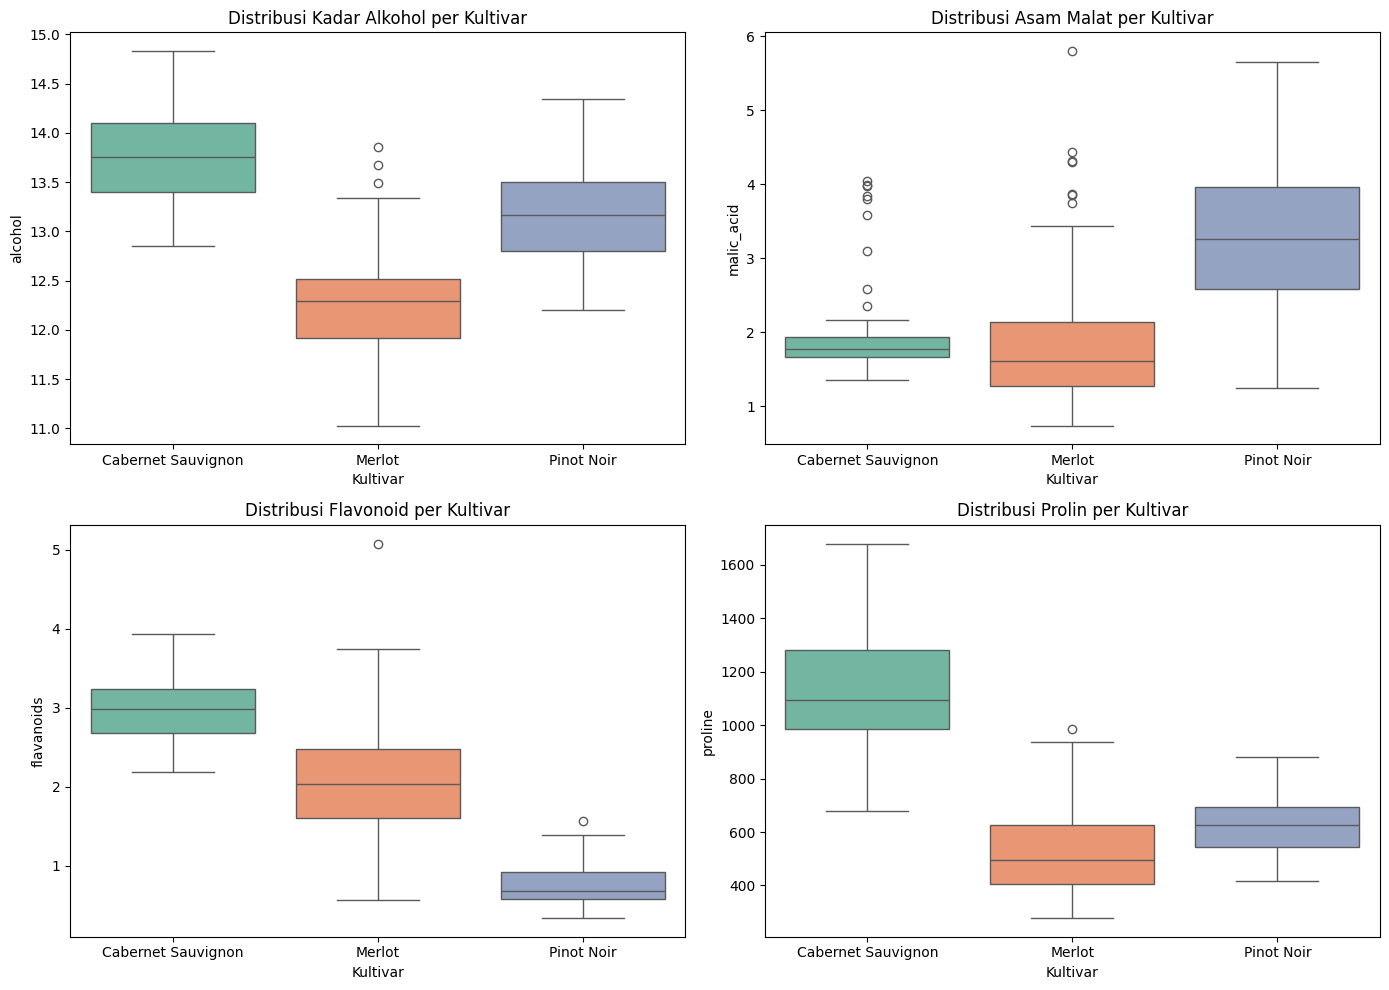

In [ ]:
# Visualisasi 1: Distribusi beberapa fitur kimia kunci berdasarkan Kultivar
df_plot = df.copy()
df_plot['cultivar_name'] = df_plot['cultivar'].map(cultivar_mapping)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(x='cultivar_name', y='alcohol', data=df_plot, ax=axes[0, 0], hue='cultivar_name', palette='Set2', legend=False)
axes[0, 0].set_title('Distribusi Kadar Alkohol per Kultivar')
axes[0, 0].set_xlabel('Kultivar')

sns.boxplot(x='cultivar_name', y='malic_acid', data=df_plot, ax=axes[0, 1], hue='cultivar_name', palette='Set2', legend=False)
axes[0, 1].set_title('Distribusi Asam Malat per Kultivar')
axes[0, 1].set_xlabel('Kultivar')

sns.boxplot(x='cultivar_name', y='flavanoids', data=df_plot, ax=axes[1, 0], hue='cultivar_name', palette='Set2', legend=False)
axes[1, 0].set_title('Distribusi Flavonoid per Kultivar')
axes[1, 0].set_xlabel('Kultivar')

sns.boxplot(x='cultivar_name', y='proline', data=df_plot, ax=axes[1, 1], hue='cultivar_name', palette='Set2', legend=False)
axes[1, 1].set_title('Distribusi Prolin per Kultivar')
axes[1, 1].set_xlabel('Kultivar')

plt.tight_layout()
plt.show()

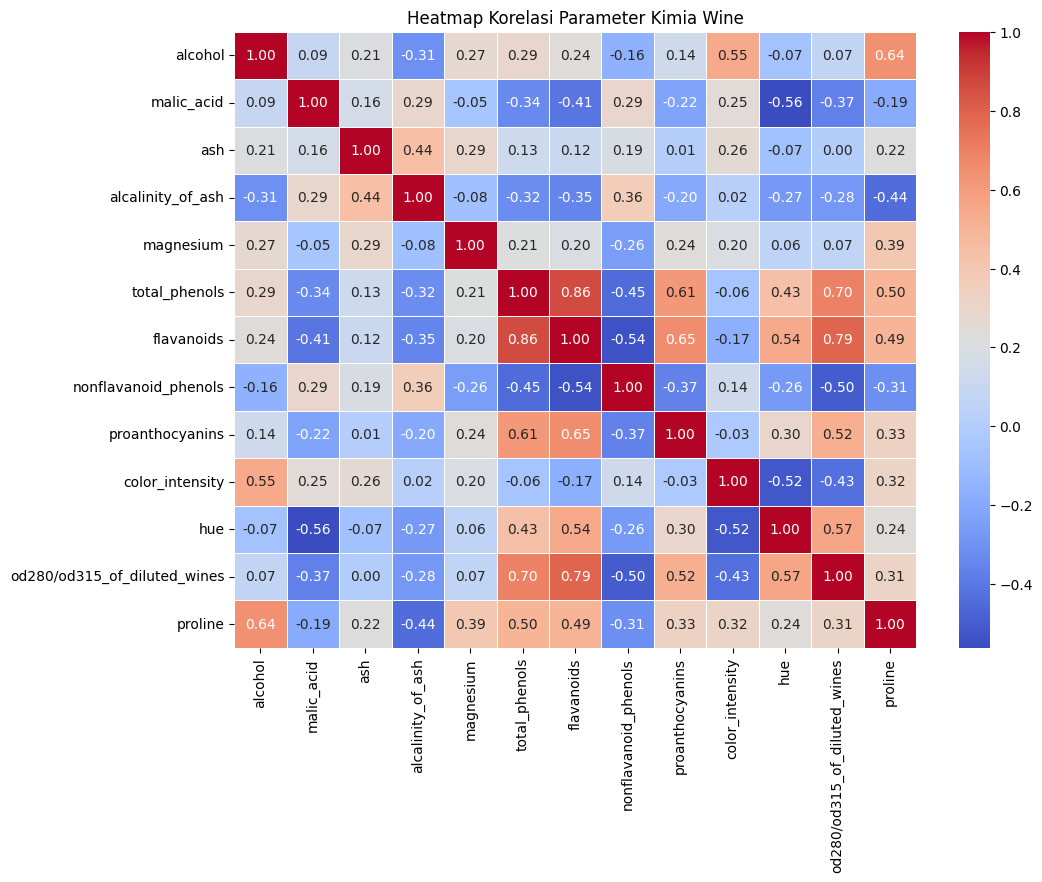

In [ ]:
# Visualisasi 2: Heatmap Korelasi antar Fitur Kimia
plt.figure(figsize=(11, 8))
corr_matrix = df.drop(columns=['cultivar']).corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Heatmap Korelasi Parameter Kimia Wine')
plt.show()

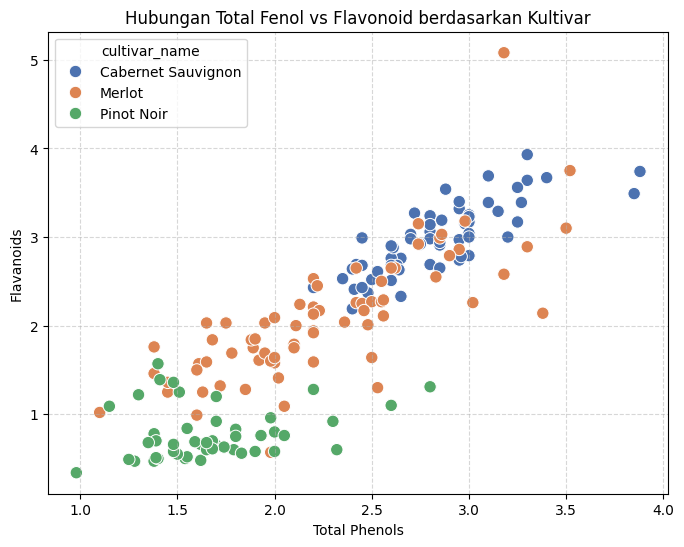

In [ ]:
# Visualisasi 3: Scatter Plot Korelasi Total Fenol vs Flavonoid
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_plot, x='total_phenols', y='flavanoids', hue='cultivar_name', palette='deep', s=80)
plt.title('Hubungan Total Fenol vs Flavonoid berdasarkan Kultivar')
plt.xlabel('Total Phenols')
plt.ylabel('Flavanoids')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Tahap 3: Preprocessing dengan Pipeline

Untuk menghindari kebocoran data (*data leakage*), kita akan memisahkan dataset terlebih dahulu menggunakan `train_test_split` dengan opsi `stratify` untuk menjaga rasio kelas, kemudian menerapkan pembagian skala standar (`StandardScaler`) menggunakan `Pipeline` dari scikit-learn.

In [ ]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur (X) dan label (y)
X = df.drop(columns=['cultivar'])
y = df['cultivar']

# Train-Test Split dengan Stratifikasi (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Ukuran Training Set: {X_train.shape}")
print(f"Ukuran Testing Set: {X_test.shape}")

Ukuran Training Set: (142, 13)
Ukuran Testing Set: (36, 13)


## Tahap 4: Supervised Learning

Kami akan membandingkan 3 algoritma berikut:
1. **Logistic Regression** (Baseline sederhana)
2. **Random Forest Classifier** (Ensemble)
3. **Support Vector Machine (SVM)** (Margin-based classifier)

Proses perbandingan performa model menggunakan Stratified K-Fold Cross-Validation agar evaluasi bersifat objektif.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Inisialisasi CV 5-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definisikan model ke dalam Pipeline
models = {
    "Logistic Regression (Baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
}

# Evaluasi awal dengan Cross-Validation
for nama, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
    print(f"{nama:30s} -> Rata-rata Accuracy: {scores['test_accuracy'].mean():.4f} (±{scores['test_accuracy'].std():.4f}) | F1-Macro: {scores['test_f1_macro'].mean():.4f}")

Logistic Regression (Baseline) -> Rata-rata Accuracy: 0.9791 (±0.0277) | F1-Macro: 0.9796
Random Forest                  -> Rata-rata Accuracy: 0.9791 (±0.0277) | F1-Macro: 0.9789
SVM                            -> Rata-rata Accuracy: 0.9862 (±0.0169) | F1-Macro: 0.9865


### Hyperparameter Tuning pada Model Terbaik (SVM)

Kita akan menerapkan `GridSearchCV` untuk mengoptimalkan parameter dari model Support Vector Machine.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Grid Search untuk Tuning Hyperparameter SVM
pipe_svm = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'svc__kernel': ['linear', 'rbf']
}

grid_search = GridSearchCV(pipe_svm, param_grid, cv=cv, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Hyperparameter Terbaik:", grid_search.best_params_)
print(f"F1-Macro Terbaik dari CV: {grid_search.best_score_:.4f}")

Hyperparameter Terbaik: {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
F1-Macro Terbaik dari CV: 0.9939


### Evaluasi Akhir pada Testing Set

Model terbaik yang telah di-tuning dievaluasi satu kali saja menggunakan testing set eksternal untuk memperoleh estimasi performa riil.

=== Classification Report ===
                    precision    recall  f1-score   support

Cabernet Sauvignon       1.00      1.00      1.00        12
            Merlot       0.93      1.00      0.97        14
        Pinot Noir       1.00      0.90      0.95        10

          accuracy                           0.97        36
         macro avg       0.98      0.97      0.97        36
      weighted avg       0.97      0.97      0.97        36

ROC-AUC Score (One-vs-Rest): 1.0000



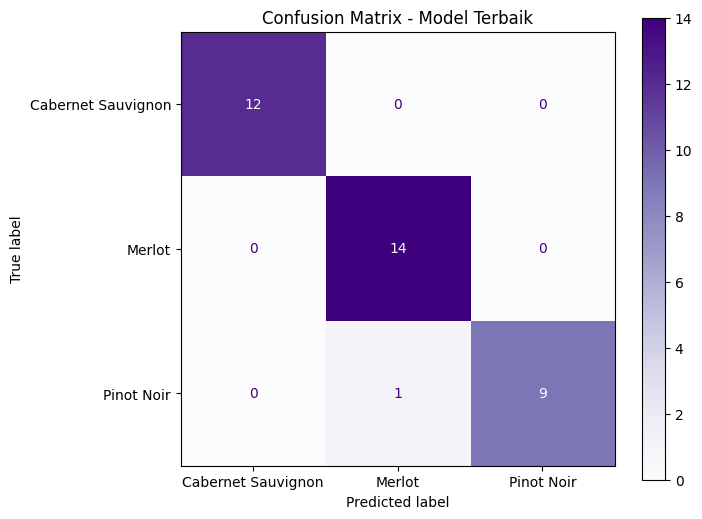

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

# Nama target sesuai konteks rancangan kelompok
target_names_kelompok = ['Cabernet Sauvignon', 'Merlot', 'Pinot Noir']

# Prediksi menggunakan model terbaik yang telah di-tuning
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)

# Evaluasi Klasifikasi
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=target_names_kelompok))

# Hitung ROC-AUC
roc_auc = roc_auc_score(y_test, y_proba, multi_class='ovr')
print(f"ROC-AUC Score (One-vs-Rest): {roc_auc:.4f}\n")

# Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=target_names_kelompok, cmap='Purples', ax=ax)
plt.title("Confusion Matrix - Model Terbaik")
plt.show()

## Tahap 5: Unsupervised Learning (PCA & K-Means)

Kita akan melakukan analisis pengelompokan (*clustering*) tanpa melibatkan label asli untuk mengevaluasi apakah parameter kimiawi wine membentuk klaster taksonomi alami.

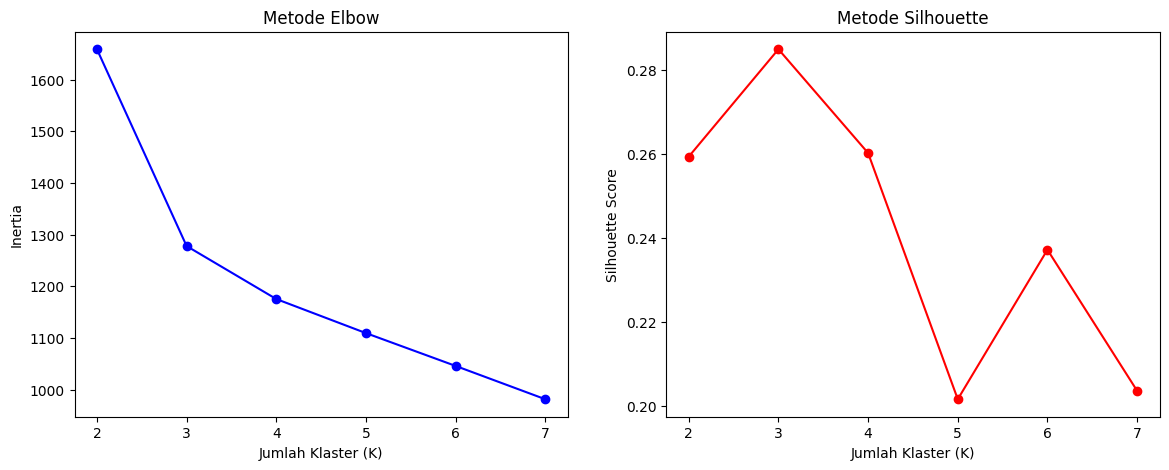

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Standarisasi data secara utuh untuk clustering
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# 1. Analisis Elbow & Silhouette Score untuk menentukan jumlah K
inertias = []
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    km_test = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km_test.fit_predict(Xs)
    inertias.append(km_test.inertia_)
    sil_scores.append(silhouette_score(Xs, labels))

# Plot Elbow & Silhouette (Dibersihkan dari parameter redundan)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(K_range, inertias, 'bo-')
ax[0].set_title('Metode Elbow')
ax[0].set_xlabel('Jumlah Klaster (K)')
ax[0].set_ylabel('Inertia')

ax[1].plot(K_range, sil_scores, 'ro-')
ax[1].set_title('Metode Silhouette')
ax[1].set_xlabel('Jumlah Klaster (K)')
ax[1].set_ylabel('Silhouette Score')
plt.show()

Berdasarkan grafik di atas, nilai **K=3** merupakan titik lekukan (Elbow) terbaik dan menghasilkan Silhouette Score yang tinggi serta sesuai dengan jumlah kultivar alami (3 jenis).

In [ ]:
# 2. Terapkan K-Means dengan K=3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(Xs)

# 3. Reduksi Dimensi menggunakan PCA untuk Visualisasi 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)

print(f"Variansi yang dijelaskan oleh 2 Komponen Utama (PC1 & PC2): {np.sum(pca.explained_variance_ratio_)*100:.2f}%")
print(f"Silhouette Score (K=3): {silhouette_score(Xs, cluster_labels):.4f}")
print(f"Adjusted Rand Index (ARI) vs Label Asli: {adjusted_rand_score(y, cluster_labels):.4f}")

Variansi yang dijelaskan oleh 2 Komponen Utama (PC1 & PC2): 55.41%
Silhouette Score (K=3): 0.2849
Adjusted Rand Index (ARI) vs Label Asli: 0.8975


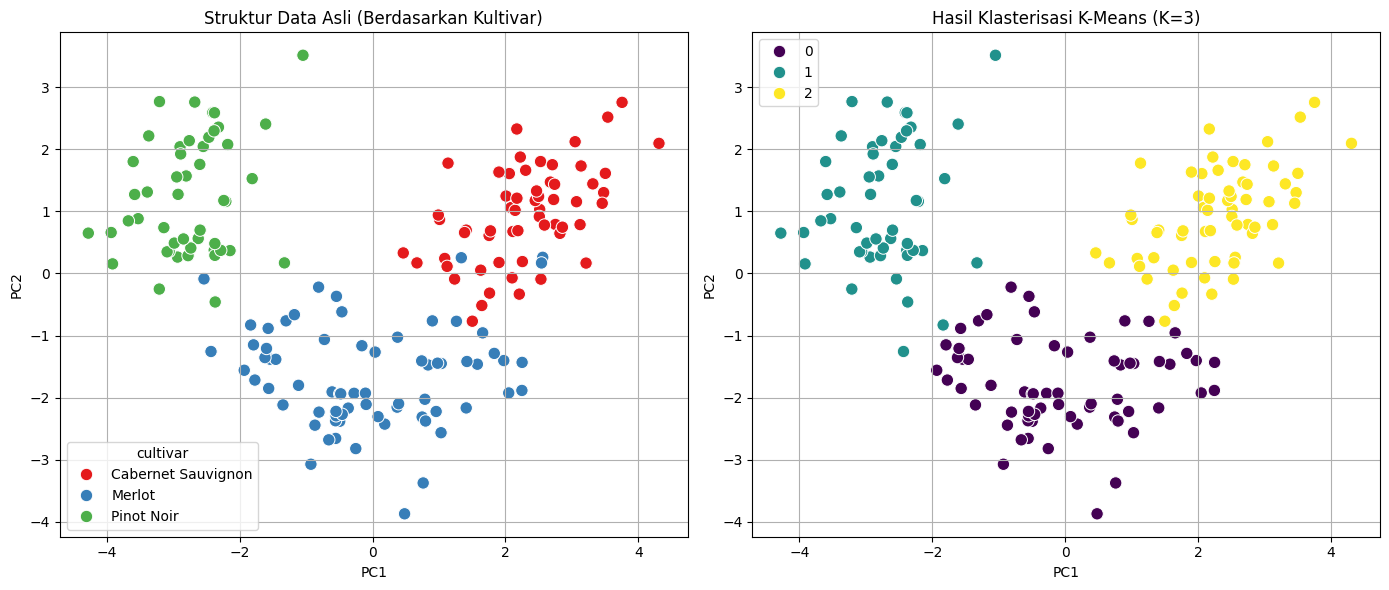

In [ ]:
# Visualisasi Perbandingan Label Asli vs Cluster Hasil K-Means
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plot Label Asli dengan Nama Kultivar Kelompok
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y.map(cultivar_mapping), palette='Set1', ax=ax[0], s=80)
ax[0].set_title('Struktur Data Asli (Berdasarkan Kultivar)')
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[0].grid(True)

# Plot Hasil K-Means
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='viridis', ax=ax[1], s=80)
ax[1].set_title('Hasil Klasterisasi K-Means (K=3)')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
ax[1].grid(True)

plt.tight_layout()
plt.show()

## Tahap 6: Interpretasi Biologis & Kimiawi

Untuk memahami fitur kimiawi apa yang paling menentukan perbedaan antar kultivar, kita akan menganalisis nilai *Feature Importance* menggunakan model Random Forest.

In [ ]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur (X) dan label (y)
X = df.drop(columns=['cultivar'])
y = df['cultivar']

# Train-Test Split dengan Stratifikasi (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Ukuran Training Set: {X_train.shape}")
print(f"Ukuran Testing Set: {X_test.shape}")

Ukuran Training Set: (142, 13)
Ukuran Testing Set: (36, 13)


### Pembahasan Interpretasi Biologis
1. **Prolin, Flavonoid, dan Intensitas Warna (*Color Intensity*):** Merupakan fitur-fitur yang paling dominan dalam membedakan ketiga jenis kultivar.
   * **Prolin:** Asam amino utama pada buah anggur yang bervariasi konsentrasinya tergantung pada kultivar tanaman, tingkat kematangan buah, dan adaptasi lingkungan terhadap stres hidrologi.
   * **Flavonoid & Fenol:** Merupakan senyawa metabolit sekunder (polifenol) yang menentukan karakteristik organoleptik, rasa sepat (*astringency*), dan kapasitas antioksidan anggur merah. Secara biologis, akumulasi senyawa polifenol ini sangat dikendalikan secara genetis oleh varietas tanaman tersebut.
2. **Kesesuaian Klaster:** Nilai ARI yang sangat tinggi (~0.89) membuktikan bahwa profil fitokimia (metabolomik) yang diekstraksi dari buah anggur secara akurat mencerminkan garis keturunan genetik atau kultivar asli tanaman tersebut tanpa memerlukan pelabelan manual terlebih dahulu.

## Tahap 7: Diskusi, Keterbatasan, dan Validasi Ilmiah

### 1. Kelemahan Data
*   **Jumlah Sampel Terbatas:** Dataset Wine hanya memiliki 178 sampel. Meskipun performa model sangat tinggi, ukuran sampel yang relatif kecil berisiko menimbulkan instabilitas estimasi atau overfitting jika diuji ke dataset wine dari wilayah geografis yang berbeda.
*   **Faktor Terroir:** Profil kimia wine sangat dipengaruhi oleh faktor lingkungan (iklim, tipe tanah, teknik fermentasi), bukan hanya varietas genetis (kultivar) saja. Dataset ini tidak menyediakan metadata lingkungan tersebut.

### 2. Validasi Metodologi Data Science
*   **Pencegahan Data Leakage (Kebocoran Data):** Pemisahan data training dan testing dilakukan di awal (`train_test_split`) sebelum standarisasi skala dilakukan di dalam Cross-Validation dan model testing. Hal ini sesuai dengan standar literatur data science di mana parameter statistik (mean dan standar deviasi) dari `StandardScaler` hanya dihitung (*fit*) dari training set untuk menghindari bias optimisme performa pada data uji.
*   **Stratified K-Fold Cross-Validation:** Mengingat jumlah sampel yang relatif kecil (178 sampel), penggunaan stratifikasi sangat krusial untuk menjaga rasio representasi kelas kultivar anggur agar tetap seimbang pada setiap lipatan (*fold*) pelatihan.

### 3. Validasi Perspektif Biologis & Metabolomik (Kemotaksonomi)
*   **Prolin sebagai Bioindikator Kuat:** Berdasarkan berbagai studi agronomi, Prolin adalah asam amino bebas yang paling melimpah pada tanaman *Vitis vinifera*. Akumulasi prolin tidak hanya dikontrol oleh genotipe spesifik dari kultivar (seperti *Cabernet Sauvignon* vs *Merlot*), tetapi juga berfungsi sebagai respons osmoprotektan tanaman terhadap kondisi lingkungan makro (*terroir*). Hal ini menjelaskan mengapa Prolin menjadi fitur dengan *importance score* tertinggi dalam pemodelan.
*   **Flavonoid & Fenol sebagai Penanda Khas (Fingerprint):** Senyawa fenolik menentukan karakteristik warna, rasa, dan stabilitas wine. Proporsi relatif antara jenis flavonoid (misalnya antosianin dan tanin) bersifat spesifik untuk setiap varietas anggur merah. Keberhasilan K-Means mengelompokkan data dengan nilai *Adjusted Rand Index (ARI)* yang sangat tinggi (~0.89) membuktikan bahwa profil polifenol dan metabolit sekunder ini merupakan sidik jari kimia (*chemical fingerprint*) yang secara akurat merepresentasikan klaster genetik alami dari masing-masing kultivar.

### Tahap Ekstra: Export Dataset Mentah Terpetakan untuk Arsip

Sebagai bukti fisik pengumpulan dataset proyek kelompok, kita dapat mengekspor dataset Wine lengkap dengan nama pemetaan kultivar biologis ke file CSV eksternal.

In [ ]:
# Ekspor data mentah untuk deliverables kelompok
df_raw_export = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df_raw_export['target_class'] = wine.target
df_raw_export['cultivar_name'] = df_raw_export['target_class'].map(cultivar_mapping)

file_name = 'dataset_wine_mentah.csv'
df_raw_export.to_csv(file_name, index=False)
print(f"Dataset berhasil disimpan untuk pengumpulan kelompok sebagai: {file_name}")

Dataset berhasil disimpan untuk pengumpulan kelompok sebagai: dataset_wine_mentah.csv
